In [23]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy.interpolate import griddata
from scipy.interpolate import RegularGridInterpolator
from scipy.integrate import cumulative_trapezoid


# DATA 



In [24]:
''' GEOMETRY & MASS '''
m_curb = 1195 #kg
m_driver = 75 #kg
m_ice = 120
m = m_curb + m_driver + m_ice #kg
length = 3.999 #m
width = 1.775 #m
height = 1.597 #m
L = 2.570 #m
b_cg = 0.56*L #m
c_cg = 0.44*L #m
h_cg = 0.49 #m

'''TRANSMISSION & TIRE '''
# 19 inches rim; /39.37 converts inches in meters; 0.7*155 is thickness of tire
D_wheel = (( 19 / 39.37 ) + ( 155 * 0.7 * 2)*10**-3)
eta_t = 0.95 #-
i_gear = 9.665 #-
f0 = 0.008
f2 = 0.4e-7
R_e = 0.339 #m

''' ENGINE '''
P_1p = 125e3 #W
P_1n = 75e3 #W
C_max = 250 #Nm
omega_b = 4800 * (2*np.pi / 60) #rad/s
E_bat = 22.6e3 #Wh
J_mot = 0.025 #kg m^2

'''RANGE EXTENDER'''
P1_ice = 28e3 #W
omega1_ice = 5000 * (2*np.pi/60) #RPM
C2_ice = 56 #Nm
omega2_ice = 4500 * (2*np.pi/60) #RPM
n_cyl = 2
V_d = 647e-6 #m**3
stroke = 66 #mm
bore = 79 #mm
P_max_gen = 26.6e3 #W
fuel_tank = 9 #L
i_gen = 2
eta_ice_to_gen = 0.975


''' OTHER '''
g = 9.81 #m/s**2
rho = 1.23 #kg/m**3
S = 2.38 #m**2
C_x = 0.3 #-

''' GENERATOR '''
C_max_gen = 80 #Nm (based on figure in statement, approximation)
omega_b_gen = 5000 * (2*np.pi/60) #rad/s (based on figure in statement, approximation)
rpm_b_gen = 5000 # RPM
P_max_gen = C_max_gen * omega_b_gen #W

# ENGINE CURVES

In [25]:
rpm_ice = np.linspace(500, 5000, 10000)
omega_ice = rpm_ice*(2*np.pi/60)

''' POWER LAW APPROXIMATION '''

P1 = P1_ice
P2 = C2_ice * omega2_ice
b = ( (omega1_ice/omega2_ice) - 1 ) / ( (P1/P2) - 1 )
a = (P1 - P2) / (np.abs(omega1_ice - omega2_ice)**b)
P_law = P1 - a*np.abs(omega_ice-omega1_ice)**b
C_law = P_law/omega_ice

''' POLYNOMIAL FIT OF ORDER 3 '''

n2 = omega2_ice/omega1_ice
A_3 = np.array([
    [1,1,1],
    [n2,n2**2,n2**3],
    [0,1,2*n2]
])
B_3 = np.array([
    1,
    P2/P1,
    0
])
X = np.linalg.solve(A_3,B_3)
a0 = 0
a1,a2,a3 = X
P_poly3 = P1* (a0 + a1*(omega_ice/omega1_ice) + a2*(omega_ice/omega1_ice)**2 + a3*(omega_ice/omega1_ice)**3)
C_poly3 = P_poly3/omega_ice

''' POLYNOMIAL FIT OF ORDER 4 '''
A_4 = np.array([
    [1,1,1,1],
    [1,2,3,4],
    [n2,n2**2,n2**3,n2**4],
    [0,1,2*n2,3*n2**2]
])
B_4 = np.array([
    1,
    0,
    P2/P1,
    0
])
Y = np.linalg.solve(A_4,B_4)
a11,a22,a33,a44 = Y
P_poly4 = P1* (a0 + a11*(omega_ice/omega1_ice) + a22*(omega_ice/omega1_ice)**2 + a33*(omega_ice/omega1_ice)**3 + a44*(omega_ice/omega1_ice)**4)
C_poly4 = P_poly4/omega_ice

''' FINAL TUNED CURVES BASED ON POLYNOMIAL FIT OF ORDER 4 '''

idx2500rpm = np.argmin(np.abs(rpm_ice - 2500))
P_below2500 = P_poly4[idx2500rpm]
C_below2500 = C_poly4[idx2500rpm]

P_final = np.zeros(len(rpm_ice))
C_final = np.zeros(len(rpm_ice))

for i in range(len(rpm_ice)):
    if rpm_ice[i] >= 2500:
        P_final[i] = P_poly4[i]
        C_final[i] = C_poly4[i]
    else :
        P_final[i] = C_below2500 * omega_ice[i]
        C_final[i] = C_below2500


# PLOTS

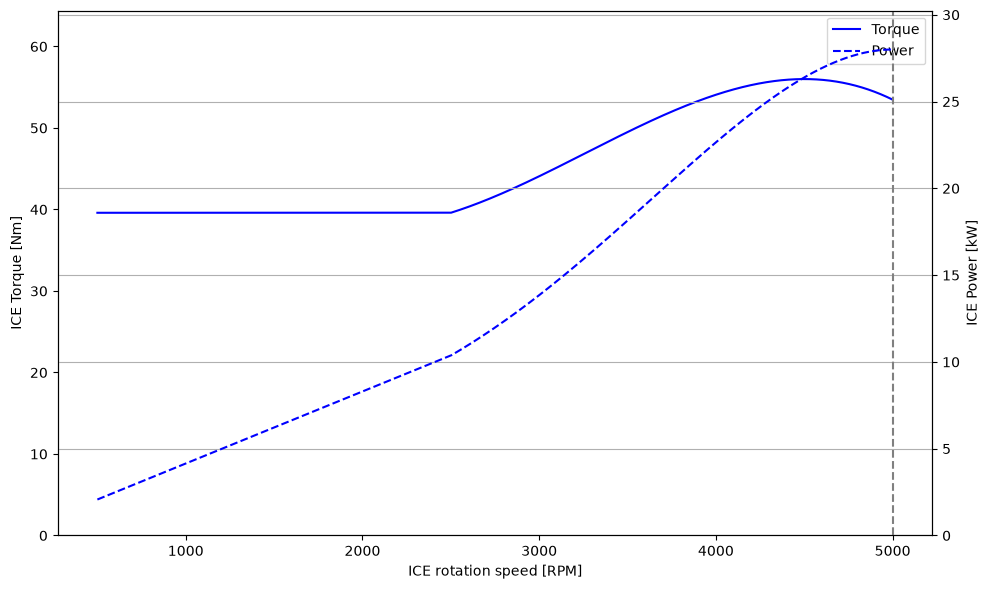

In [26]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Left axis : Torques
line1 = ax1.plot(rpm_ice, C_final, label='Torque', color='blue')
ax1.set_xlabel('ICE rotation speed [RPM]')
ax1.set_ylabel('ICE Torque [Nm]')
ax1.tick_params(axis='y')

# Right axis : Powers
ax2 = ax1.twinx()
line2 = ax2.plot(rpm_ice, P_final*10**-3, linestyle='--', label='Power', color='blue')
ax2.set_ylabel('ICE Power [kW]')
ax2.tick_params(axis='y')
ax2.grid(False) # Either 2 grids mixed, awful

# Scaling
ax1.set_ylim(0, C2_ice * 1.15)
ax2.set_ylim(0, (P1_ice*10**-3) * 1.08)

# Base speed
plt.axvline(x=rpm_b_gen, linestyle='dashed', color='gray', label='Base speed')

# Legend
lines = line1 + line2 
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels)
plt.tight_layout()
plt.grid(True)
plt.show()

# BSFC


In [27]:
c0 = 4.726e2
c1 = -5.426e-2
c2 = -7.736
c3 = 9.845e-6
c4 = 1.308e-4
c5 = 9.346e-2

rpm_grid_ice = np.linspace(500, 5000, 6000)
T_grid_ice = np.linspace(0, 56, 6000)
rpm_grid_ice, T_grid_ice = np.meshgrid(rpm_grid_ice, T_grid_ice)

bsfc = c0 + c1*rpm_grid_ice + c2*T_grid_ice + c3*rpm_grid_ice**2 + c4*rpm_grid_ice*T_grid_ice + c5*T_grid_ice**2

# PLOTS

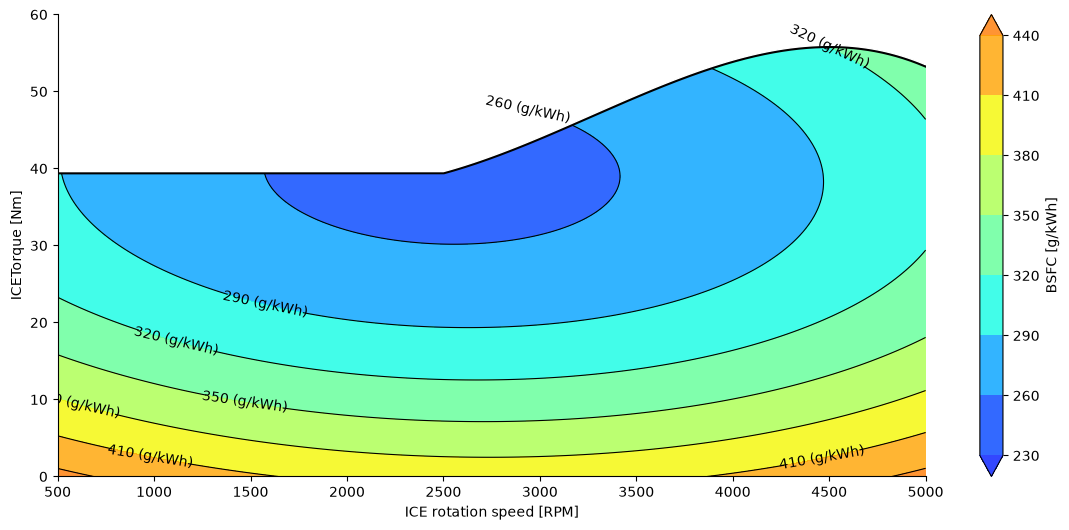

In [28]:
fig, ax = plt.subplots(figsize=(14, 6))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Contour lines of BSFC (lowest value, largest value, step)
levels = np.arange(230, 450, 30)
cs = ax.contour(rpm_grid_ice, T_grid_ice, bsfc, levels=levels, colors='k', linewidths=0.8, alpha=1)
ax.clabel(cs, inline=True, fontsize=10, fmt='%1.0f (g/kWh)')

# Special Color map
cmap_eff = LinearSegmentedColormap.from_list('jet_soft', plt.cm.jet(np.linspace(0.15, 0.78, 256)))
cf = ax.contourf(rpm_grid_ice, T_grid_ice, bsfc, levels=levels, cmap=cmap_eff, alpha=0.8, extend='both')
fig.colorbar(cf, ax=ax, label='BSFC [g/kWh]')

ax.plot(rpm_ice, C_final, color='black', linewidth=4)
ax.fill_between(rpm_ice, C_final, 500, color='white', zorder=2) # Hide above torque curve
ax.set_xlim(500, 5000)
ax.set_ylim(0, 60)
ax.set_xlabel('ICE rotation speed [RPM]')
ax.set_ylabel('ICETorque [Nm]')
plt.show()

# EFFICIENCY

In [29]:
rpm_gen = np.linspace(1, 12000, 10000)
omega_gen = rpm_gen*(2*np.pi/60)

''' GENERATOR TORQUE AND POWER CURVES '''

C_gen = np.zeros_like(omega_gen)
P_gen = np.zeros_like(omega_gen)
for i in range(len(omega_gen)):
    if omega_gen[i] <= omega_b_gen:
        C_gen[i] = C_max_gen
        P_gen[i] = C_max_gen * omega_gen[i]
    else:
        P_gen[i] = P_max_gen
        C_gen[i] = P_max_gen / omega_gen[i]


''' EFFICIENCY MAP '''

d0 = 9.071e-1
d1 = 1.358e-5
d2 = 1.149e-3
d3 = -3.662e-9
d4 = 6.036e-7
d5 = -6.612e-5
d6 = 1.734e-13
d7 = -1.434e-11
d8 = -3.817e-9
d9 = 5.683e-7

rpm_grid_gen = np.linspace(0, 12000, 6000)
T_grid_gen = np.linspace(0, 80, 6000)
rpm_grid_gen, T_grid_gen = np.meshgrid(rpm_grid_gen, T_grid_gen)

eta_gen = d0 + d1*rpm_grid_gen + d2*T_grid_gen + d3*rpm_grid_gen**2 + d4*rpm_grid_gen*T_grid_gen + d5*T_grid_gen**2 + d6*rpm_grid_gen**3 + d7*rpm_grid_gen**2 * T_grid_gen + d8*rpm_grid_gen*T_grid_gen**2 + d9*T_grid_gen**3

# PLOTS

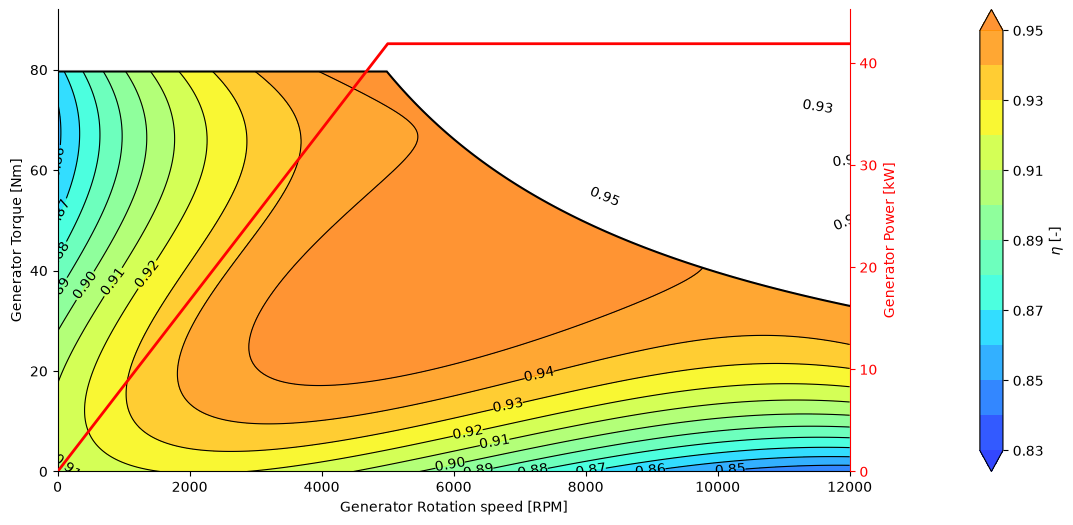

In [30]:
fig, ax = plt.subplots(figsize=(14, 6))
ax2 = ax.twinx()                             # axe de droite = puissance

# Contour lines of effciency (lowest value, largest value, step)
levels = np.arange(0.83, 0.96, 0.01)
cs = ax.contour(rpm_grid_gen, T_grid_gen, eta_gen, levels=levels, colors='k', linewidths=0.8, alpha=1)
ax.clabel(cs, inline=True, fontsize=10)

# Color map
cf = ax.contourf(rpm_grid_gen, T_grid_gen, eta_gen, levels=levels, cmap=cmap_eff, alpha=0.8, extend='both')
fig.colorbar(cf, ax=ax, pad=0.12, label=r'$\eta$ [-]') # Avoir color bar in power axis

# Torque
ax.plot(rpm_gen, C_gen, color='black', linewidth=4)
ax.fill_between(rpm_gen, C_gen, 500, color='white', zorder=2)

# Power
ax2.plot(rpm_gen, P_gen*10**-3, color='red', linewidth=2)


ax.set_xlim(0, 12000)
ax.set_ylim(0, C_max_gen * 1.15)
ax2.set_ylim(0, P_max_gen * 10**-3 * 1.08)
ax.set_xlabel('Generator Rotation speed [RPM]')
ax.set_ylabel('Generator Torque [Nm]')
ax2.set_ylabel('Generator Power [kW]', color='red')
ax2.tick_params(axis='y', colors='red')

# Spines
ax.spines[['top', 'right']].set_visible(False)
ax2.spines[['top', 'left', 'bottom']].set_visible(False)
ax2.spines['right'].set_color('red')

plt.show()

# ELECTRICAL POWER

In [31]:
''' ELECTRICAL POWER OUT OF GENERATOR'''

P_elec = np.zeros(len(omega_ice)) # variation of electrical power wrt to ICE working point

rpm_el = rpm_grid_gen[0, :]  
T_el = T_grid_gen[:, 0]

for i in range(len(omega_ice)):
  # Impact of reduction ratio from ICE to generator
  omega_ice_to_gen = omega_ice[i] * i_gen
  torque_ice_to_gen = C_final[i] / i_gen

  # Indices in generator map
  idx_omega = np.argmin(np.abs(rpm_el - omega_ice_to_gen))
  idx_torque = np.argmin(np.abs(T_el - torque_ice_to_gen))

  # Efficiency value
  efficiency = eta_gen[idx_omega, idx_torque]  
  
  P_elec[i] = omega_ice[i] * C_final[i] * eta_ice_to_gen * efficiency


# PLOTS


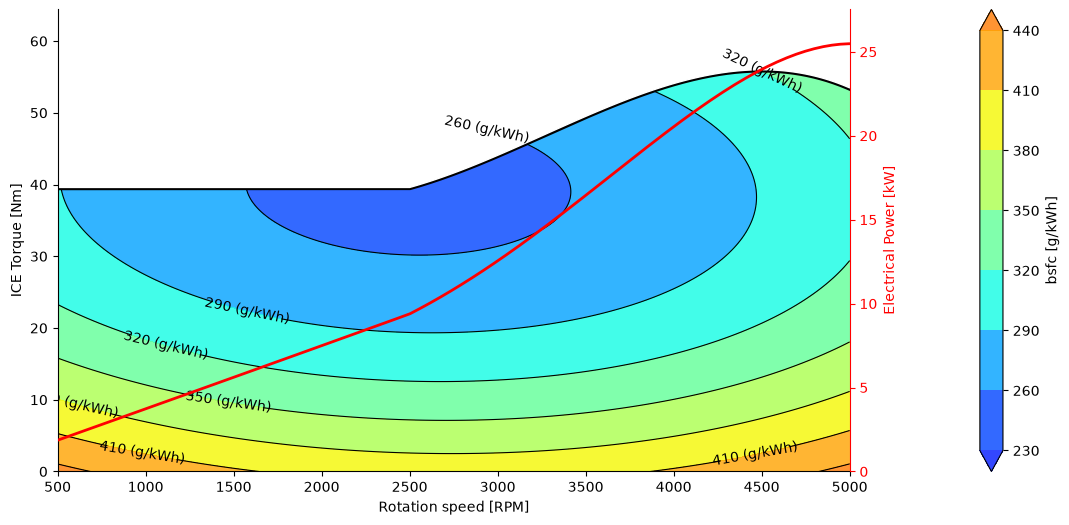

In [32]:
fig, ax = plt.subplots(figsize=(14, 6))
ax2 = ax.twinx()                             # axe de droite = puissance

# Cartographie de rendement (axe couple)
levels = np.arange(230, 450, 30)
cf = ax.contourf(rpm_grid_ice, T_grid_ice, bsfc, levels=levels, cmap=cmap_eff, alpha=0.8, extend='both')
cs = ax.contour(rpm_grid_ice, T_grid_ice, bsfc, levels=levels, colors='k', linewidths=0.8, alpha=1)
ax.clabel(cs, inline=True, fontsize=10, fmt='%1.0f (g/kWh)')

# Courbe de couple + masque blanc au-dessus
ax.plot(omega_ice / (2 * np.pi) * 60, C_final, color='black', linewidth=4)
ax.fill_between(omega_ice / (2 * np.pi) * 60, C_final, 500, color='white', zorder=2)

# Courbe de puissance (axe de droite)
ax2.plot(omega_ice / (2 * np.pi) * 60, P_elec*10**-3, color='red', linewidth=2)

# Limites
ax.set_xlim(500, 5000)
ax.set_ylim(0, np.max(C_final) * 1.15)
ax2.set_ylim(0, np.max(P_elec) * 10**-3 * 1.08)

# Labels
ax.set_xlabel('Rotation speed [RPM]')
ax.set_ylabel('ICE Torque [Nm]')
ax2.set_ylabel('Electrical Power [kW]', color='red')
ax2.tick_params(axis='y', colors='red')

# Spines
ax.spines[['top', 'right']].set_visible(False)
ax2.spines[['top', 'left', 'bottom']].set_visible(False)
ax2.spines['right'].set_color('red')

# Colorbar décalée pour ne pas chevaucher l'axe de puissance
fig.colorbar(cf, ax=ax, pad=0.12, label=r'bsfc [g/kWh]')

plt.show()

# BATTERY MANAGEMENT STRATEGY

In [33]:
''' BEST EFFICIENT ICE OPERATING POINT SELECTION'''

# Extracting all operating points (rpm,torque) inside sweet spot (bsfc <= 260)
mask = bsfc <= 260
rpm_extracted = rpm_grid_ice[mask]
T_extracted = T_grid_ice[mask]
bsfc_extracted = bsfc[mask]

# Final matrix will be such that each row correponds to a point (rpm, torque, efficiency, P_el)
matrix_data = np.column_stack((rpm_extracted, T_extracted))

# From ICE to generator
rpm_1d_gen = np.linspace(0, 12000, 6000)
T_1d_gen = np.linspace(0, 80, 6000)

eta_gen_interpolator = RegularGridInterpolator(
    (T_1d_gen, rpm_1d_gen), eta_gen, bounds_error=False, fill_value=None
) #interpolation to have values for every point

rpm_gen_vals = rpm_extracted * i_gen
omega_gen_vals = rpm_gen_vals * (2 * np.pi / 60)
T_gen_vals = T_extracted * eta_ice_to_gen / i_gen

points_gen = np.column_stack((T_gen_vals, rpm_gen_vals)) #instead of a loop that runs each point
eta_gen_vals = eta_gen_interpolator(points_gen)

# Final matrix update
matrix_data = np.column_stack((matrix_data, eta_gen_vals))

# Electrical power
P_mech_gen_vals = T_gen_vals * omega_gen_vals
P_el_vals = P_mech_gen_vals * eta_gen_vals

# Final matrix final update
matrix_data = np.column_stack((matrix_data, P_el_vals))

# Since criterion is to maximize driving range, the operating should be such that
# the amount of fuel consumed to produce 1 kWh of electrical energy is minimum.
# Introduction of electrical equivalent bsfc considering efficiencies 
bsfc_el_vals = bsfc_extracted / (eta_ice_to_gen * eta_gen_vals)

best_idx = np.argmin(bsfc_el_vals)
best_row = matrix_data[best_idx]

# Affichage des résultats pour le meilleur point
print("--- Best operating point to maximize driving range ---")
#print(f"Line index : {best_idx}")
print(f"ICE Rotation speed : {best_row[0]:.2f} RPM")
print(f"ICE Torque : {best_row[1]:.2f} Nm")
print(f"Generator Efficiency : {best_row[2]*100:.2f} %")
print(f"Electrical Power (P_el) : {best_row[3]:.2f} W")
print(f"Electrical Equivalent BSFC : {bsfc_el_vals[best_idx]:.2f} g/kWh")

--- Best operating point to maximize driving range ---
ICE Rotation speed : 2431.57 RPM
ICE Torque : 40.42 Nm
Generator Efficiency : 95.17 %
Electrical Power (P_el) : 9550.76 W
Electrical Equivalent BSFC : 271.28 g/kWh


In [34]:
"""
plt.figure(figsize=(10, 6))

RPM_grid_gen, T_grid_gen_map = np.meshgrid(rpm_1d_gen, T_1d_gen)

# Efficiency map
contour = plt.contourf(
    RPM_grid_gen,
    T_grid_gen_map,
    eta_gen,
    levels=25,
    cmap=cmap_eff,
    origin="lower",
    extend="both",
)
cbar = plt.colorbar(contour)
cbar.set_label("Generator Efficiency (%)", fontsize=11)

levels = np.arange(0.83, 0.96, 0.01)
cs = plt.contour(rpm_grid_gen, T_grid_gen, eta_gen, levels=levels, colors='k', linewidths=0.8, alpha=1)
plt.clabel(cs, inline=True, fontsize=10)

plt.plot(rpm_gen, C_gen, color='black', linewidth=4)
plt.fill_between(rpm_gen, C_gen, 500, color='white', zorder=2)

# Operating points tested
plt.scatter(
    rpm_gen_vals,
    T_gen_vals,
    color="crimson",
    s=20,
    alpha=0.7,
    edgecolors="k",
    linewidths=0.4,
    label="Tested Points (BSFC ≤ 260 g/kWh)",
)

# Best efficient operating point
best_rpm_gen = best_row[0] * i_gen
best_T_gen = best_row[1] * eta_ice_to_gen / i_gen
plt.scatter(
    best_rpm_gen,
    best_T_gen,
    color="gold",
    s=180,
    marker="*",
    edgecolors="black",
    linewidths=1,
    zorder=5,
    label="Best Energy Compromise",
)


plt.xlabel("Generator rotation speed (RPM)", fontsize=11)
plt.ylabel("Generator Torque (Nm)", fontsize=11)
plt.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.ylim(0, np.max(C_gen) * 1.15)

plt.tight_layout()
plt.show()
"""

'\nplt.figure(figsize=(10, 6))\n\nRPM_grid_gen, T_grid_gen_map = np.meshgrid(rpm_1d_gen, T_1d_gen)\n\n# Efficiency map\ncontour = plt.contourf(\n    RPM_grid_gen,\n    T_grid_gen_map,\n    eta_gen,\n    levels=25,\n    cmap=cmap_eff,\n    origin="lower",\n    extend="both",\n)\ncbar = plt.colorbar(contour)\ncbar.set_label("Generator Efficiency (%)", fontsize=11)\n\nlevels = np.arange(0.83, 0.96, 0.01)\ncs = plt.contour(rpm_grid_gen, T_grid_gen, eta_gen, levels=levels, colors=\'k\', linewidths=0.8, alpha=1)\nplt.clabel(cs, inline=True, fontsize=10)\n\nplt.plot(rpm_gen, C_gen, color=\'black\', linewidth=4)\nplt.fill_between(rpm_gen, C_gen, 500, color=\'white\', zorder=2)\n\n# Operating points tested\nplt.scatter(\n    rpm_gen_vals,\n    T_gen_vals,\n    color="crimson",\n    s=20,\n    alpha=0.7,\n    edgecolors="k",\n    linewidths=0.4,\n    label="Tested Points (BSFC ≤ 260 g/kWh)",\n)\n\n# Best efficient operating point\nbest_rpm_gen = best_row[0] * i_gen\nbest_T_gen = best_row[1] * et

# MOTOR CURVES (BATTERY FULL)

In [35]:
theta0 = np.arctan(0)

v_kmh = np.linspace(0,150,11400) #km/h; 150 is max speed given in litterature
v_ms = v_kmh/3.6

F_grading0 = m*g*np.sin(theta0)
P_grading0 = F_grading0 * v_ms
F_AERO = 0.5*rho*S*C_x*(v_ms**2)
P_AERO = F_AERO * v_ms
F_RR0  = m*g*(f0 + f2*(v_kmh**2))*np.cos(theta0)
P_RR0  = F_RR0 * v_ms
F_RES0 = F_grading0 + F_AERO + F_RR0
P_RES0 = P_grading0 + P_AERO + P_RR0

omega = np.linspace(1*(2*np.pi)/60, 11400*(2*np.pi)/60, 11400)
rpm = omega*60/(2*np.pi)

P_nom = np.zeros_like(omega)
C_nom = np.zeros_like(omega)

# The base speed should be kept beween nominal & peak regimes, so a new torque
# value should be determined by knowing omega_b
C_max_nom = P_1n/omega_b
for j in range(len(omega)):
  if omega[j] <= (P_1n/C_max_nom):
    P_nom[j] = C_max_nom*omega[j]
  else:
    P_nom[j] = P_1n
C_nom = P_nom/omega

v_ms_t = (omega*R_e)/i_gear
v_kmh_t = v_ms_t*3.6

# Traction force and power
F_t = (eta_t * C_nom * i_gear)/R_e
P_t = F_t * v_ms

F_net = F_t - F_RES0
P_net = P_t - P_RES0

m_e = (m-m_driver)*(1.04 + (J_mot/((m_curb+m_ice)*R_e**2))*i_gear**2) #effective mass
accel_capa = m_e/F_net


# PERFORMANCE (FULL BATTERY)

In [36]:
""" --------------------Greatest therotecial maximum speed-------------------------- """
max_iter = 1000
tol = 1e-4
v_0 = 1 # arbitrary choice
A_v = (m*g*np.sin(theta0)) + (m*g*f0*np.cos(theta0))
B_v = (0.5 * rho * S * C_x) + (m*g*(f2/12.96)*np.cos(theta0))

# Computation of v_max_max and ideal gear ratio
i=0
for i in range(max_iter):
  if i==0:
    v_next = ( ((eta_t * P_1n) - (A_v * v_0)) / B_v )**(1/3)
    v_act = v_next

  else :
    v_next = ( ((eta_t * P_1n) - (A_v * v_act)) / B_v )**(1/3)

    if (np.abs(v_next - v_act) < tol ) :
      break
    else:
      v_act = v_next

v_max_max = v_next
print("Theorical greatest maximum speed: ", v_max_max * 3.6, "km/h")
omega_max = 11400 * (2*np.pi/60)
ideal_i = ((omega_max) * R_e) / v_max_max
print("Ideal gear ratio to reach v_max_max: ", ideal_i)


""" ----------------Real greatest maximum speed---------------------- """
v_act_bis = 150/3.6
for k in range(max_iter):
    omega_max = 11399*(2*np.pi)/60
    omega_k = min(v_act_bis*i_gear/R_e,omega_max)
    P_k = eta_t *C_nom[int(omega_k * 60 / (2*np.pi))] *omega_k

    v_new = ((P_k - (A_v * v_act_bis)) / B_v) ** (1/3)

    if abs(v_new - v_act_bis) < tol:
        break
    v_act_bis = v_new
v_power = v_new
v_rpm = ((11400 * (2*np.pi) / 60) * R_e) / i_gear
v_max = min(v_rpm, v_power)
#print(f"{v_power*3.6:.2f}")
print(f"Real greatest maximum speed: {v_max*3.6:.2f} km/h")

""" ---------------------Greatest slope from rest------------------------ """
mu = 0.8

max_slope1 = 100 * ( ((mu * b_cg / L) - f0) / ( 1 - (mu * h_cg / L) ) )
print("Maximum slope in 1st gear : ",max_slope1, "%")

""" ---------------------Greatest slope from 80kph----------------------- """
F_t_80 = np.interp(80, v_kmh_t, F_t) #need to obtain the value for the exact 80kph speed
F_aero80 = 0.5*rho*S*C_x*(80/3.6)**2
d_80 = (F_t_80 - F_aero80) / (m*g)
max_slope80 = 100 * np.tan( np.arcsin( (d_80 - (f0 * np.sqrt(1 + f0**2 - d_80**2))) / (1 + f0**2) ) )
print("Maximum slope at 80 km/h ",max_slope80, "%")

# VERIFICATION OF TRACTION-LIMITED SLOPE
a = (m*g*(f0+(f2*80**2))) - (mu * m * g * c_cg/L)
b = (m*g) + (mu * m * g * h_cg/L)
max_slope80_adhesion = 100 * np.tan(np.arcsin(-F_aero80/(np.sqrt(a**2 + b**2))) - np.arcsin(a/(np.sqrt(a**2 + b**2))))
print("Verification que la limite de traction est plus grande que la puissance : ", max_slope80_adhesion, ">? 21%")

""" -----------------------50 to 90kph------------------------- """
v_50_90 = np.linspace(50/3.6, 90/3.6, 100)
F_net_50_90 = np.interp(v_50_90*3.6, v_kmh_t, F_net)
integral_50_90 = np.trapezoid(1/F_net_50_90,v_50_90)
time_50_90 = m_e * integral_50_90
print("Acceleration time to go from 50 km/h to 90 km/h :", time_50_90, "s")

""" --------------------------0 to 100kph------------------------- """
v_0_100 = np.linspace(1/3.6, 100/3.6, 100)
F_net_0_100 = np.interp(v_0_100*3.6, v_kmh_t, F_net)
integral_0_100 = np.trapezoid(1/F_net_0_100,v_0_100)
time_0_100 = m_e * integral_0_100
print("Acceleration time to go from 0 km/h to 100 km/h :", time_0_100, "s")

""" ---------------------------0 to 400m-------------------------- """
#aucune idee de v_finale => d'abord calculer temps et distance pour 0-150. Si en dessous de 400m =>
#imposer vitesse constante 150km/h pour derniers metres. Sinon, interpoler avant 150km/h
v_0_150 = np.linspace(1/3.6, 150/3.6, 1000)
F_net_0_150 = np.interp(v_0_150 * 3.6, v_kmh_t, F_net)
time_cumul = m_e * cumulative_trapezoid(1 / F_net_0_150, v_0_150, initial=0)
dist_cumul = m_e * cumulative_trapezoid(v_0_150 / F_net_0_150, v_0_150, initial=0)# pour stocker les valeurs dans un vecteur, utile
# pour interpoler après s'il faut
dist_150 = dist_cumul[-1]
time_150 = time_cumul[-1]

if dist_150 >= 400:
    time_400m = np.interp(400, dist_cumul, time_cumul)
    v_400m_kmh = np.interp(400, dist_cumul, v_0_150 * 3.6)
else:
    dist_restante = 400 - dist_150
    time_400m = time_150 + (dist_restante / (150/3.6))
    v_400m_kmh = 150

print("Acceleration time for 0 to 400m :", time_400m, "s")
print("Speed at 400m :", v_400m_kmh, "km/h")
print("Distance at which 150 km/h is reached :", dist_150, "m")

Theorical greatest maximum speed:  190.88381465938886 km/h
Ideal gear ratio to reach v_max_max:  7.632495604131167
Real greatest maximum speed: 150.74 km/h
Maximum slope in 1st gear :  51.91919191919193 %
Maximum slope at 80 km/h  21.630034958466567 %
Verification que la limite de traction est plus grande que la puissance :  28.390868975206608 >? 21%
Acceleration time to go from 50 km/h to 90 km/h : 4.7478131534494565 s
Acceleration time to go from 0 km/h to 100 km/h : 11.278344049744536 s
Acceleration time for 0 to 400m : 18.29092888941414 s
Speed at 400m : 129.96893935574954 km/h
Distance at which 150 km/h is reached : 689.9932633561128 m


# MOTOR CURVES (BATTERY DEPLETED)

23045.803592503533


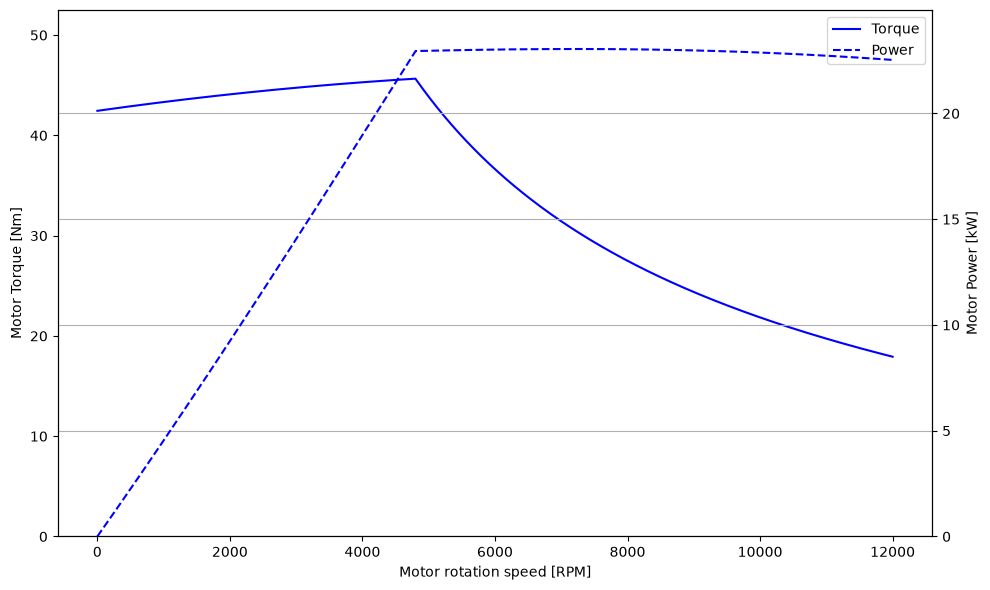

In [ ]:
""" Efficiency of electric motor function (from HW1) """
P_max = 75e3
omega_base = 4800 * 2*np.pi/60 # rad/s
T_max = P_max / omega_base  # Nm
RPM_max = 11400
omega_max = RPM_max * 2*np.pi/60
P_max_regen = 50e3  # W, max regen power
T_max_regen = T_max * P_max_regen/P_max



a1 = 8.079e-1  # [-]
a2 = 1.827e-5 * (60/(2*np.pi))  # [1/(rad/s)]
a3 = 6.760e-4  # [1/Nm]
a4 = -1.087e-9 * (60/(2*np.pi))**2  # [1/(rad/s)^2]
a5 = 2.434e-9 * (60/(2*np.pi))  # [1/Nm /(rad/s)]
a6 = -1.864e-6  # [1/nm^2]


# I normalize the coefficients by the max omega & torque
# so that i can scale for regen efficiency
a1_norm = a1
a2_norm = a2 * omega_max
a3_norm = a3 * T_max
a4_norm = a4 * omega_max**2
a5_norm = a5 * omega_max * T_max
a6_norm = a6 * T_max**2

def efficiency_motor(omega, T):
    """The efficiency of the electric motor using the Golverk formula

    Parameters:
    - omega : angular velocity of motor [rad/s] (scalar or numpy array)
    - T : torque of motor [Nm] (scalar or numpy array)

    Returns:
    - eta: efficiency of the motor
    """
    # Check if inputs are arrays or sequences
    is_array = isinstance(omega, np.ndarray) or isinstance(T, np.ndarray)

    omega_norm, T_norm = omega / omega_max, T / T_max

    if not is_array:
        # Scalar logic (original behavior)
        if (omega <= omega_base and T > T_max) or (T * omega > P_max):
            return 0.01
        eta = a1_norm + a2_norm * omega_norm +\
            a3_norm * T_norm + a4_norm * (omega_norm ** 2) +\
            a5_norm * T_norm * omega_norm + a6_norm * (T_norm ** 2)
        return eta  # * eta_t
    else:
        # Vectorized array logic
        omega = np.asarray(omega)
        T = np.asarray(T)

        eta = a1_norm + a2_norm * omega_norm +\
            a3_norm * T_norm + a4_norm * (omega_norm ** 2) +\
            a5_norm * T_norm * omega_norm + a6_norm * (T_norm ** 2)
        eta = eta  # * eta_t

        # Use element-wise logical operators (& and |) and np.where
        invalid = ((omega <= omega_base) & (T > T_max)) | ((T * omega) > P_max)
        return np.where(invalid, 0.01, eta)

def efficiency_regen(omega, T):

    is_array = isinstance(omega, np.ndarray) or isinstance(T, np.ndarray)

    omega_norm, T_norm = omega / omega_max, T / T_max_regen

    if not is_array:
        # Scalar logic (original behavior)
        if (omega <= omega_base and T > T_max_regen) or (T * omega > P_max_regen):
            return 0.01
        eta = a1_norm + a2_norm * omega_norm +\
            a3_norm * T_norm + a4_norm * (omega_norm ** 2) +\
            a5_norm * T_norm * omega_norm + a6_norm * (T_norm ** 2)
        return eta  # * eta_t
    else:
        # Vectorized array logic
        omega = np.asarray(omega)
        T = np.asarray(T)

        eta = a1_norm + a2_norm * omega_norm +\
            a3_norm * T_norm + a4_norm * (omega_norm ** 2) +\
            a5_norm * T_norm * omega_norm + a6_norm * (T_norm ** 2)
        eta = eta  # * eta_t

        # Use element-wise logical operators (& and |) and np.where
        invalid = ((omega <= omega_base) & (T > T_max_regen)) | (
            (T * omega) > P_max_regen)
        return np.where(invalid, 0.01, eta)


""" Motor curves """
"""
rpm_mot = np.linspace(1000, 10000, 10000)
omega_mot = rpm_mot * (2*np.pi/60)
C_el = P_elec / omega_mot
eta_mot = efficiency_motor(omega_mot, C_el)

C_el = C_el * eta_mot
P_el = P_elec * eta_mot
"""

rpm_mot = np.linspace(1, 12000, 10000)
omega_mot = rpm_mot * (2*np.pi/60)
C_el = np.zeros_like(omega_mot)
P_el = np.zeros_like(omega_mot)
P_max_el = np.max(P_elec)

for i in range(len(omega_mot)):
    if omega_mot[i] <= omega_base:
        C_el[i] = P_max_el / omega_base
        P_el[i] = C_el[i] * omega_mot[i]
    else :
        P_el[i] = P_max_el
        C_el[i] = P_el[i] / omega_mot[i]
eta_mot = efficiency_motor(omega_mot, C_el)
C_el = eta_mot * C_el
P_el = eta_mot * P_el


fig, ax1 = plt.subplots(figsize=(10, 6))

# Left axis : Torques
line1 = ax1.plot(rpm_mot, C_el, label='Torque', color='blue')
ax1.set_xlabel('Motor rotation speed [RPM]')
ax1.set_ylabel('Motor Torque [Nm]')
ax1.tick_params(axis='y')

# Right axis : Powers
ax2 = ax1.twinx()
line2 = ax2.plot(rpm_mot, P_el*10**-3, linestyle='--', label='Power', color='blue')
ax2.set_ylabel('Motor Power [kW]')
ax2.tick_params(axis='y')
ax2.grid(False) # Either 2 grids mixed, awful

# Scaling
ax1.set_ylim(0, np.max(C_el) * 1.15)
ax2.set_ylim(0, np.max(P_el)* 10**-3 * 1.08)

# Legend
lines = line1 + line2 
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels)
plt.tight_layout()
plt.grid(True)
plt.show()


v_ms_t_mot = (omega_mot*R_e)/i_gear
v_kmh_t_mot = v_ms_t_mot*3.6


F_grading0_mot = m*g*np.sin(theta0)
P_grading0_mot = F_grading0_mot * v_ms_t_mot
F_AERO_mot = 0.5*rho*S*C_x*(v_ms_t_mot**2)
P_AERO_mot = F_AERO_mot * v_ms_t_mot
F_RR0_mot  = m*g*(f0 + f2*(v_kmh_t_mot**2))*np.cos(theta0)
P_RR0_mot  = F_RR0_mot * v_ms_t_mot
F_RES0_mot = F_grading0_mot + F_AERO_mot + F_RR0_mot
P_RES0_mot = P_grading0_mot + P_AERO_mot + P_RR0_mot


# Traction force and power
F_t_mot = (eta_t * C_el * i_gear)/R_e
P_t_mot = F_t_mot * v_ms_t_mot

F_net_mot = F_t_mot - F_RES0_mot
P_net_mot = P_t_mot - P_RES0_mot

accel_capa_mot = m_e/F_net_mot


# PERFORMANCE (NO BATTERY)

In [38]:
""" --------------------Greatest therotecial maximum speed-------------------------- """
max_iter = 1000
tol = 1e-4
v_0 = 1 # arbitrary choice
A_v = (m*g*np.sin(theta0)) + (m*g*f0*np.cos(theta0))
B_v = (0.5 * rho * S * C_x) + (m*g*(f2/12.96)*np.cos(theta0))

# Computation of v_max_max and ideal gear ratio
i=0
for i in range(max_iter):
  if i==0:
    v_next = ( ((eta_t * np.max(P_el)) - (A_v * v_0)) / B_v )**(1/3)
    v_act = v_next

  else :
    v_next = ( ((eta_t * np.max(P_el)) - (A_v * v_act)) / B_v )**(1/3)

    if (np.abs(v_next - v_act) < tol ) :
      break
    else:
      v_act = v_next

v_max_max = v_next
print("Theorical greatest maximum speed: ", v_max_max * 3.6, "km/h")
omega_max = 10000 * (2*np.pi/60)
ideal_i = ((omega_max) * R_e) / v_max_max
print("Ideal gear ratio to reach v_max_max: ", ideal_i)


""" ----------------Real greatest maximum speed---------------------- """
v_act_bis = 30/3.6
for k in range(max_iter):
    omega_k = v_act_bis * i_gear / R_e
    rpm_k = omega_k * 60 / (2 * np.pi)
    rpm_k = min(10000, rpm_k)
    omega_k = min(omega_max, omega_k)
    torque_k = np.interp(rpm_k, rpm_mot, C_el)
    P_k = eta_t * torque_k * omega_k

    v_new = ((P_k - (A_v * v_act_bis)) / B_v) ** (1/3)

    if abs(v_new - v_act_bis) < tol:
        break
    v_act_bis = v_new
v_power = v_new
v_rpm = ((10000 * (2*np.pi) / 60) * R_e) / i_gear
v_max = min(v_rpm, v_power)
print(f"{v_power*3.6:.2f}")
print(f"Real greatest maximum speed: {v_max*3.6:.2f} km/h")

""" ---------------------Greatest slope from rest------------------------ """
mu = 0.8

max_slope1 = 100 * ( ((mu * b_cg / L) - f0) / ( 1 - (mu * h_cg / L) ) )
print("Maximum slope in 1st gear : ",max_slope1, "%")

""" ---------------------Greatest slope from 80kph----------------------- """
F_t_80_mot = np.interp(80, v_kmh_t_mot, F_t_mot) #need to obtain the value for the exact 80kph speed
F_aero80_mot = 0.5*rho*S*C_x*(80/3.6)**2
d_80_mot = (F_t_80_mot - F_aero80_mot) / (m*g)
max_slope80_mot = 100 * np.tan( np.arcsin( (d_80_mot - (f0 * np.sqrt(1 + f0**2 - d_80_mot**2))) / (1 + f0**2) ) )
print("Maximum slope at 80 km/h ",max_slope80_mot, "%")

# VERIFICATION OF TRACTION-LIMITED SLOPE
a_mot = (m*g*(f0+(f2*80**2))) - (mu * m * g * c_cg/L)
b_mot = (m*g) + (mu * m * g * h_cg/L)
max_slope80_adhesion_mot = 100 * np.tan(np.arcsin(-F_aero80_mot/(np.sqrt(a_mot**2 + b_mot**2))) - np.arcsin(a_mot/(np.sqrt(a_mot**2 + b_mot**2))))
print("Verification que la limite de traction est plus grande que la puissance : ", max_slope80_adhesion_mot, ">? 1.16%")

""" -----------------------50 to 90kph------------------------- """
v_50_90_mot = np.linspace(50/3.6, 90/3.6, 100)
F_net_50_90_mot = np.interp(v_50_90_mot*3.6, v_kmh_t_mot, F_net_mot)
integral_50_90_mot = np.trapezoid(1/F_net_50_90_mot,v_50_90_mot)
time_50_90_mot = m_e * integral_50_90_mot
print("Acceleration time to go from 50 km/h to 90 km/h :", time_50_90_mot, "s")

""" --------------------------0 to 100kph------------------------- """
v_0_100_mot = np.linspace(1/3.6, 100/3.6, 100)
F_net_0_100_mot = np.interp(v_0_100_mot*3.6, v_kmh_t_mot, F_net_mot)
integral_0_100_mot = np.trapezoid(1/F_net_0_100_mot,v_0_100_mot)
time_0_100_mot = m_e * integral_0_100_mot
print("Acceleration time to go from 0 km/h to 100 km/h :", time_0_100_mot, "s")

""" ---------------------------0 to 400m-------------------------- """
#aucune idee de v_finale => d'abord calculer temps et distance pour 0-150. Si en dessous de 400m =>
#imposer vitesse constante 150km/h pour derniers metres. Sinon, interpoler avant 150km/h
v_0_120_mot = np.linspace(1/3.6, 120/3.6, 1000)
F_net_0_120_mot = np.interp(v_0_120_mot * 3.6, v_kmh_t_mot, F_net_mot)
time_cumul_mot = m_e * cumulative_trapezoid(1 / F_net_0_120_mot, v_0_120_mot, initial=0)
dist_cumul_mot = m_e * cumulative_trapezoid(v_0_120_mot / F_net_0_120_mot, v_0_120_mot, initial=0)# pour stocker les valeurs dans un vecteur, utile
# pour interpoler après s'il faut
dist_120_mot = dist_cumul_mot[-1]
time_120_mot = time_cumul_mot[-1]

if dist_120_mot >= 400:
    time_400m_mot = np.interp(400, dist_cumul_mot, time_cumul_mot)
    v_400m_kmh_mot = np.interp(400, dist_cumul_mot, v_0_120_mot * 3.6)
else:
    dist_restante_mot = 400 - dist_120_mot
    time_400m_mot = time_120_mot + (dist_restante_mot / (120/3.6))
    v_400m_kmh_mot = 120

print("Acceleration time for 0 to 400m :", time_400m_mot, "s")
print("Speed at 400m :", v_400m_kmh_mot, "km/h")
print("Distance at which 120 km/h is reached :", dist_120_mot, "m")

Theorical greatest maximum speed:  124.06707637595703 km/h
Ideal gear ratio to reach v_max_max:  10.300878595765731
122.57
Real greatest maximum speed: 122.57 km/h
Maximum slope in 1st gear :  51.91919191919193 %
Maximum slope at 80 km/h  1.168503594639561 %
Verification que la limite de traction est plus grande que la puissance :  28.390868975206608 >? 1.16%
Acceleration time to go from 50 km/h to 90 km/h : 89.85618558368225 s
Acceleration time to go from 0 km/h to 100 km/h : 188.16350606490968 s
Acceleration time for 0 to 400m : 61.30408972524126 s
Speed at 400m : 44.78439986071356 km/h
Distance at which 120 km/h is reached : 7059.1109901000555 m


# ENERGY CONSUMPTION

Energy consumption at 30.0 km/h : 5.048 (kWh/100km)
Fuel consumption at 30.0 km/h : 1.826 (L/100km)

Energy consumption at 50.0 km/h : 6.850 (kWh/100km)
Fuel consumption at 50.0 km/h : 2.478 (L/100km)

Energy consumption at 100.0 km/h : 15.407 (kWh/100km)
Fuel consumption at 100.0 km/h : 5.573 (L/100km)

Energy consumption at 120.0 km/h : 20.548 (kWh/100km)
Fuel consumption at 120.0 km/h : 7.432 (L/100km)



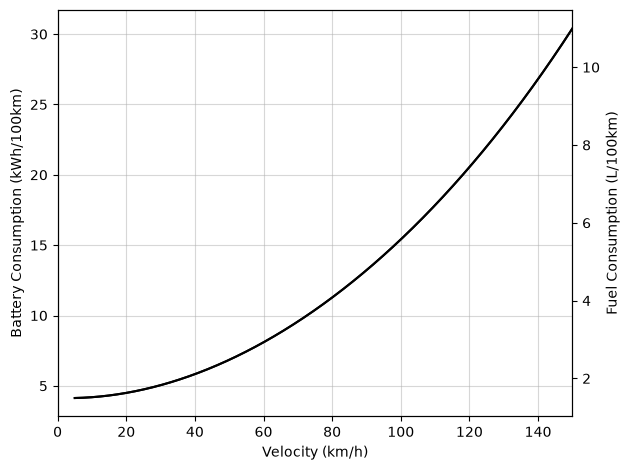

In [39]:
def F_res(v, theta):
    F_rr = (f0 + f2 * v**2) * m * g * np.cos(theta)
    F_aero = 0.5 * rho* S * C_x * v**2
    F_slope = m * g * np.sin(theta)

    return F_rr + F_aero + F_slope


def F_acc(m_e, dv_dt):
    return m_e * dv_dt


""" Constant speed """

v = np.array([30, 50, 100, 120]) / 3.6  # velocities to test, kmh to m/s


# Energy consumption per km = F * 1km (J/km) /(1000*3600) (=>kwh/km)
for i in range(len(v)):
    omega = (v[i] / R_e) * i_gear
    torque = (F_res(v[i], 0) * R_e) / (i_gear * eta_t)

    F_mot = (F_res(v[i], 0)) / \
        eta_t / (efficiency_motor(omega, torque) * eta_t)
    energy_kwh_100km = (F_mot * 1000.0 / 36000.0)
    energy_bsfc = bsfc_el_vals[best_idx] #g / kWh
    energy_bsfc_l_kWh = energy_bsfc / 750 #750g/L => L/kWh
    energy_bsfc_l_100km = energy_bsfc_l_kWh * energy_kwh_100km # L/100km

    print(
        f"Energy consumption at {v[i] * 3.6:.1f} km/h : {energy_kwh_100km:.3f} (kWh/100km)")
    print(
        f"Fuel consumption at {v[i] * 3.6:.1f} km/h : {energy_bsfc_l_100km:.3f} (L/100km)\n")

# =======================================
# 6B : Constant speeds curves consumption
# =======================================

v = np.linspace(5, 150, 1000) / 3.6  # km/h to m/s

omega = (v / R_e) * i_gear
torque = (F_res(v, 0) * R_e) / (i_gear * eta_t)

F_mot = F_res(v, 0) / eta_t / efficiency_motor(omega, torque) / eta_t
energy_kwh_100km = F_mot * 1000.0 / 36000.0

energy_bsfc = bsfc_el_vals[best_idx]          # g/kWh
energy_bsfc_l_kWh = energy_bsfc / 750         # 750 g/L => L/kWh
energy_bsfc_l_100km = energy_bsfc_l_kWh * energy_kwh_100km  # L/100km

c1, c2 = "tab:blue", "tab:orange"

fig, ax1 = plt.subplots()
ax2 = ax1.twinx()                              # second y-axis

l1, = ax1.plot(v * 3.6, energy_kwh_100km, color='black')
l2, = ax2.plot(v * 3.6, energy_bsfc_l_100km, color='black')

ax1.set_xlabel("Velocity (km/h)")
ax1.set_ylabel("Battery Consumption (kWh/100km)", color='black')
ax2.set_ylabel("Fuel Consumption (L/100km)", color='black')
ax1.tick_params(axis="y", colors='black')
ax2.tick_params(axis="y", colors='black')

ax1.set_xlim(0, 150)
ax1.grid(alpha=0.5)                            # grid on one axis only, otherwise the lines won't align



fig.tight_layout()
plt.show()

# WLTP

Total Energy: 2.826 kWh
Total Distance: 23.262 km
WLTP Consumption: 12.15 kWh/100km
 Autonomy (km) : 154.78030454455637


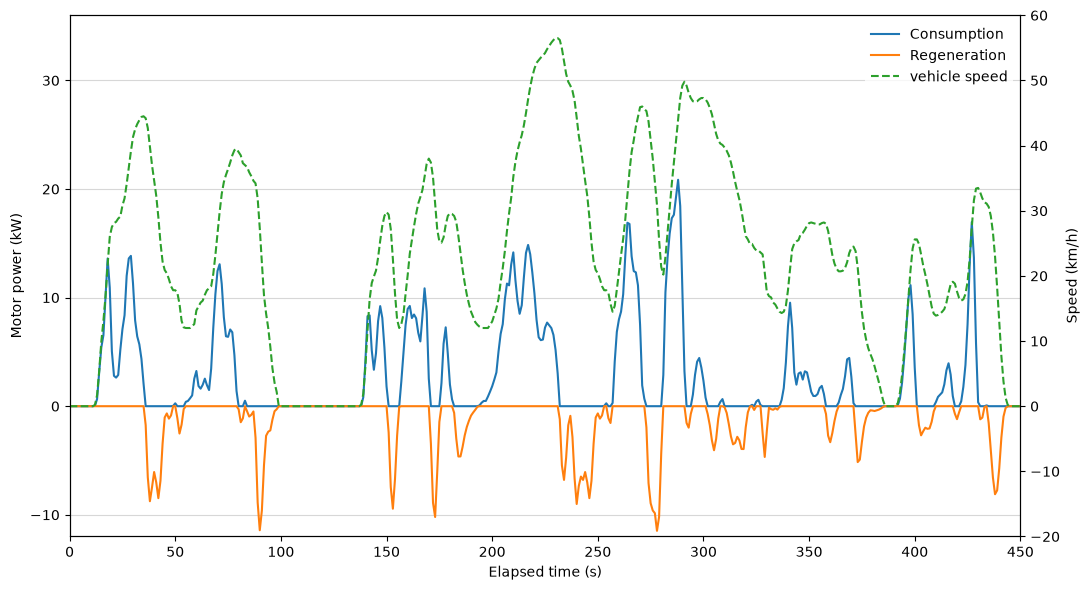

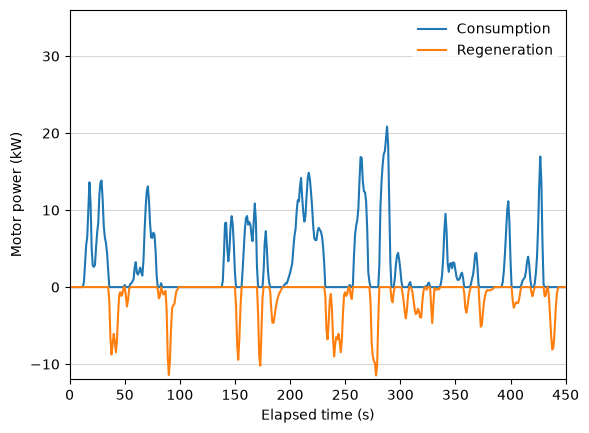

In [40]:
alpha_regen = 1.0
battery_capacity = 18.8

df = pd.read_excel("WLTP.xlsx", skiprows=0, decimal=",")

phase = df['Phase'].to_numpy()[1:]  # string says which phase we are in
total_time = df['Total elapsed time'].to_numpy()[1:]  # [s]
phase_time = df['Phase elapsed time'].to_numpy()[1:]  # [s]
speed = df['WLTC class 3, version 5, vehicle speed'].to_numpy()[1:]  # [km/h]
speed = speed / 3.6  # [m/s]
dv_dt = np.gradient(speed, total_time)
delta_t = 1  # [s]
delta_x = speed * delta_t
E_tot = 0  # J, cumulative


def Power_regen(v, dv_dt):
    """The absolute value of regen power, following chap 5 slide 14 convention
    The way the max regen power is handled is : 
    compute the mechanical power, multiplied by motor efficiency => gives the electrical power delivered to the battery
    then cap this power to the battery at 50kW
    By capping after having computed the efficiency we could apply the efficiency in an extrapolated region (beyond T_max & P_max)
    but if we applied capping onto mechanical power we would never reach the 50kW power delivered to battery
    """

    # net force available for regen (deleration is due partly to f_res)
    F_mot = (F_acc(m_e, dv_dt) + F_res(v, 0))

    omega = (v / R_e) * i_gear
    torque = abs((F_mot * R_e) / (i_gear * eta_t))
    eta = efficiency_regen(omega, torque) * eta_t

    P_mot = F_mot * v

    if P_mot >= 0:
        return 0.0
    else:
        P_bat = np.abs(P_mot) * eta * alpha_regen
        return min(50000, P_bat)


def Power_consumption(v, dv_dt):
    # tractive force by motor = force to accelerate + to fight road resistance
    F_mot = (F_acc(m_e, dv_dt) + F_res(v, 0))

    omega = (v / R_e) * i_gear
    torque = abs((F_mot * R_e) / (i_gear * eta_t))
    eta = efficiency_motor(omega, torque) * eta_t

    P_mot = F_mot * v

    if P_mot < 0:
        return 0.0
    else:
        P_bat = np.abs(P_mot) / eta
        return P_bat


p_cons_array = np.zeros(len(total_time))  # array for debug
p_regen_array = np.zeros(len(total_time))  # array for debug
total_distance = np.sum(speed * delta_t)
T_WLTP = np.zeros(len(total_time))
omega_WLTP = np.zeros(len(total_time))

for i in range(len(speed)):
    p_cons_array[i] = Power_consumption(float(speed[i]), float(dv_dt[i]))
    p_regen_array[i] = -Power_regen(float(speed[i]), float(dv_dt[i]))
    E_tot += Power_consumption(speed[i], dv_dt[i]) * delta_t
    E_tot -= Power_regen(speed[i], dv_dt[i]) * delta_t
    omega_WLTP[i] = speed[i] * i_gear/R_e

    F_mot = (F_acc(m_e, dv_dt[i]) + F_res(speed[i], 0))
    T_WLTP[i] = F_mot * R_e/i_gear


E_tot_kWh = E_tot / 3_600_000.0
total_distance_km = total_distance / 1000.0
WLTP_consumption = (E_tot_kWh / total_distance_km) * 100.0

print(f"Total Energy: {E_tot_kWh:.3f} kWh")
print(f"Total Distance: {total_distance_km:.3f} km")
print(f"WLTP Consumption: {WLTP_consumption:.2f} kWh/100km")
print(f" Autonomy (km) : {battery_capacity / WLTP_consumption * 100}")

# ======================================
# Plot the P vs time of the WLTP Cycle
# ======================================

fig, ax = plt.subplots(1, 1, figsize=(11, 6))

# Primary axis (left) - Power
line1 = ax.plot(total_time, p_cons_array / 1000,
                label="Consumption", color="tab:blue")
line2 = ax.plot(total_time, p_regen_array / 1000,
                label="Regeneration", color="tab:orange")
ax.set_xlabel(r"Elapsed time (s)")
ax.set_ylabel(r"Motor power (kW)")

# Secondary axis (right) - Speed
ax_speed = ax.twinx()
line3 = ax_speed.plot(total_time, speed*3.6,
                      label="vehicle speed", color="tab:green", linestyle="--")
ax_speed.set_ylabel(r"Speed (km/h)")  # update unit as needed

# Combine handles and labels into a single unified legend
lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax.legend(lines, labels, loc="best", frameon=True,
          facecolor="white", edgecolor="none")

ax.set_xlim(0, 450)
ax.set_ylim(-12, 36)
ax_speed.set_ylim(-20, 60)
ax.grid(True, axis='y',  alpha=0.5)
plt.tight_layout()


plt.show()


fig, ax = plt.subplots()

# Primary axis (left) - Power
line1 = ax.plot(total_time, p_cons_array / 1000,
                label="Consumption", color="tab:blue")
line2 = ax.plot(total_time, p_regen_array / 1000,
                label="Regeneration", color="tab:orange")
ax.set_xlabel(r"Elapsed time (s)")
ax.set_ylabel(r"Motor power (kW)")

# Secondary axis (right) - Speed

# Combine handles and labels into a single unified legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax.legend(lines, labels, loc="best", frameon=True,
          facecolor="white", edgecolor="none")

ax.set_xlim(0, 450)
ax.set_ylim(-12, 36)
ax.grid(True, axis='y',  alpha=0.5)


plt.show()

